In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy
import squarify
try:
    import piplite
    await piplite.install(['ipywidgets'])
except ImportError:
    pass
import ipywidgets as widgets
import json

today = date.today()

**combining datasets and reducing precision**

In [24]:
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
DHS_per_f = datadir + 'regions_25kb_CT20230214.DHS.factornormNMF.sum_enrich_corank_percentile.hdf5'
epi_per_f = datadir + 'regions_25kb_CT20230214.epilogos.statesum_rank_percentile.hdf5'

# load region percentiles
DHS_per, DHS_factors, DHS_color = load_per(DHS_per_f)
epi_per, epi_factors, epi_color = load_per(epi_per_f)

In [25]:
percents = np.hstack((DHS_per, epi_per))
factor_order = np.append(DHS_factors, epi_factors)
metric_order = np.append(np.array(['DHSs'] * len(DHS_factors)),
                         np.array(['chromatin states'] *
                                  len(epi_factors)))
colors = np.append(DHS_color, epi_color)

In [61]:
percents.shape

(88036, 34)

In [62]:
out_f = datadir + 'regions_25kb_CT20230321.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.npy'
print(out_f)
np.save(out_f, percents.astype('float32'))

/home/ctrader/AG/NarrativeGenomics/region_narration/data/regions_25kb_CT20230321.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.npy


**moving factor information to json file**

In [32]:
factor_arr = []
for f, m, c, o in zip(factor_order, metric_order, colors, range(len(factor_order))):
    factor_arr.append(
        {
            'name': f.replace('_', '/'),
            'metric': m,
            'color': c,
            'ind': o
        }
    )

In [33]:
json.dumps(factor_arr)

'[{"name": "Placental/trophoblast", "metric": "DHSs", "color": "#FFE500", "ind": 0}, {"name": "Lymphoid", "metric": "DHSs", "color": "#FE8102", "ind": 1}, {"name": "Myeloid/erythroid", "metric": "DHSs", "color": "#FF0000", "ind": 2}, {"name": "Cardiac", "metric": "DHSs", "color": "#07AF00", "ind": 3}, {"name": "Musculoskeletal", "metric": "DHSs", "color": "#4C7D14", "ind": 4}, {"name": "Vascular/endothelial", "metric": "DHSs", "color": "#414613", "ind": 5}, {"name": "Primitive/embryonic", "metric": "DHSs", "color": "#05C1D9", "ind": 6}, {"name": "Neural", "metric": "DHSs", "color": "#0467FD", "ind": 7}, {"name": "Digestive", "metric": "DHSs", "color": "#009588", "ind": 8}, {"name": "StromalA", "metric": "DHSs", "color": "#BB2DD4", "ind": 9}, {"name": "StromalB", "metric": "DHSs", "color": "#7A00FF", "ind": 10}, {"name": "Renal/cancer", "metric": "DHSs", "color": "#4A6876", "ind": 11}, {"name": "Cancer/epithelial", "metric": "DHSs", "color": "#08245B", "ind": 12}, {"name": "Pulmonarydev

**optimizing functions**

loading data - hdf5

In [71]:
t = time.time()

datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
DHS_per_f = datadir + 'regions_25kb_CT20230214.DHS.factornormNMF.sum_enrich_corank_percentile.hdf5'
epi_per_f = datadir + 'regions_25kb_CT20230214.epilogos.statesum_rank_percentile.hdf5'

# load region percentiles
DHS_per, DHS_factors, DHS_color = load_per(DHS_per_f)
epi_per, epi_factors, epi_color = load_per(epi_per_f)

# join data from each metric
join_data_per_metric(DHS_per, DHS_factors, DHS_color, epi_per, epi_factors, epi_color)

print(time.time() - t)

0.9674258232116699


loading data - compressed tsv

In [72]:
t = time.time()

datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
per_f = datadir + 'regions_25kb_CT20230321.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.npy'

percents = np.load(per_f)

print(time.time() - t)

0.009004831314086914


loading regions - old

In [134]:
t = time.time()
regions_path = datadir + 'hg38.25kb.maxMean.CT20230118.sorted.bed'

f = open(regions_path, 'r')
regions = []
regions_sep = []
for line in f.readlines():
    line = line.strip().split('\t')
    regions_sep.append(line)
    regions.append(line[0] + ':' + line[1] + '-' + line[2])
f.close()
regions_sep = np.array(regions_sep)

print(time.time() - t)

0.3315892219543457


In [126]:
# out_f = datadir + 'hg38.25kb.maxMean.CT20230118.sorted.bed.npy'
# print(out_f)
# np.save(out_f, regions_sep)

/home/ctrader/AG/NarrativeGenomics/region_narration/data/hg38.25kb.maxMean.CT20230118.sorted.bed.npy


loading regions - new

In [143]:
t = time.time()
regions_path = datadir + 'hg38.25kb.maxMean.CT20230118.sorted.bed.npy'

regions_sep = np.load(regions_path)

print(time.time() - t)

0.010492324829101562


**Old functions**

In [23]:
def join_data_per_metric(DHS_per, DHS_factors, DHS_color, epi_per, epi_factors, epi_color):
    global percents, factor_order, metric_order, colors
    percents = np.hstack((DHS_per, epi_per))
    factor_order = np.append(DHS_factors, epi_factors)
    metric_order = np.append(np.array(['DHSs'] * len(DHS_factors)),
                             np.array(['chromatin states'] *
                                      len(epi_factors)))
    colors = np.append(DHS_color, epi_color)
    
    
def load_per(per_f):
    hdf5_f = h5py.File(per_f, 'r')
    percentile = hdf5_f['percentile'][:]
    factors = np.char.decode(hdf5_f['factors'][:])
    color = np.char.decode(hdf5_f['colors'][:])
    hdf5_f.close()
    return percentile, factors, color

**Final**

In [301]:
def roiURL(roi, top_regions, detail_level, target_factors_str,
           link_type='dual'):
    today = date.today()
    roiurl_name = ('region_narration_simsearch_regions_roi_' + str(roi) +
                   '_detail_level_' + str(detail_level) + '_factors_' +
                   target_factors_str + '_scale_25kb_CT' +
                   today.strftime("%Y%m%d") + '.bed')
    bed_path_name = os.path.join('/home/ctrader/public_html/', roiurl_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    link_path1 = ('https://epilogos.altius.org:1234/?application=viewer&' +
                  'sampleSet=vC&mode=single&genome=hg38&model=18&complex' +
                  'ity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=800' +
                  '0&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%' +
                  '40resources.altius.org%2F~ctrader%2F' + roiurl_name)
    link_path2 = ('https://index.altius.org:1234/?application=viewer&mod' +
                  'e=pd&chrLeft=chr11&chrRight=chr11&start=47329800&stop' +
                  '=47356800&roiURL=https%3A%2F%2Fencode%3Acollabor8%40r' +
                  'esources.altius.org%2F~ctrader%2F' + roiurl_name)
    link_path_dual = ('https://index.altius.org:3000/?application=viewer' +
                      '&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8' +
                      '%40resources.altius.org%2F~ctrader%2F' + roiurl_name)
    if link_type == 'dual':
        return link_path_dual
    else:
        return link_path1, link_path2
    

def top_region_sig(percents, top_regions):
    # mean and std of factor percentiles in all regions
    all_mean = np.mean(percents, axis=0)
    all_std = np.std(percents, axis=0)

    # mean of factor percentiles in most similar regions
    top_region_mean = np.mean(percents[top_regions[:, 1:]], axis=1)

    # Z score
    Z = (top_region_mean - all_mean) / (all_std / np.sqrt(top_regions.shape[1] - 1))

    # p-value (one sided)
    pval = stats.norm.sf(Z)

    return pval, Z


def simsearch(percents, roi, included_factors, num_similar_regions):

        # factors the query region rank highest in
    query_factor_order = np.argsort(-percents[roi])

    # factors to search over
    target_factors = query_factor_order[
        np.isin(query_factor_order, included_factors)
    ]

    # convolution
    roi_percents = percents[roi, target_factors]
    roi_conv_all = percents[:, target_factors] * roi_percents

    # fusion
    roi_sim_all = []
    for dl in range(1, len(included_factors) + 1):
        roi_sim = 1 - np.prod(1 - roi_conv_all[:, :dl], axis=1)
        roi_sim_all.append(roi_sim)
    roi_sim_all = np.array(roi_sim_all)

    # most similar regions
    top_regions = np.zeros(
        (len(included_factors), num_similar_regions + 1)
        , dtype=int
    )
    top_regions_pre = np.argsort(
        -roi_sim_all, axis=1
    )[:, :(num_similar_regions + 1)]

    for i in range(len(included_factors)):
        top_regions[i] = np.append(
            roi,
            top_regions_pre[i][
                top_regions_pre[i] != roi
            ][:num_similar_regions]
        )

    # factor percentile significance
    pval, Z = top_region_sig(percents, top_regions)

    rows = (
        np.ones(top_regions.shape, dtype=int) *
        np.arange(top_regions.shape[0]).reshape(-1, 1)
    )

    return (top_regions, roi_sim_all[rows, top_regions],
            percents[top_regions], query_factor_order, 
            target_factors, pval, Z)

In [302]:
def load_roi(genomic_location, gz_file_path):
    global roi
    if str.isalpha(str(genomic_location)[0]):
        # load roi
        gz_tb = tabix.open(gz_file_path)
        roi = np.array(
            list(gz_tb.querys(genomic_location))
        )[:, 3].astype(int)[0]
    else:
        roi = int(genomic_location)

        
def load_ranks(per_f):
    global percents
    percents = np.load(per_f)


def setup_included_factors(included_factors_str):
    global included_factors
    included_factors = np.int_(
        included_factors_str.strip('[').strip(']').split(',')
    )
    query_factors_above_thresh = np.where(percents[roi] > 0.5)[0]
    included_factors = included_factors[
        np.isin(included_factors, query_factors_above_thresh)
    ]


def read_in_genomic_coordinates(regions_path):
    global regions_sep
    regions_sep = np.load(regions_path)


def find_most_similar_region_indices(num_similar_regions):
    global top_regions, roi_sim, roi_per, query_factor_order, target_factors, pval, Z
    (top_regions, roi_sim,
     roi_per, query_factor_order,
     target_factors, pval,
     Z) = simsearch(percents, roi, included_factors, num_similar_regions)


def setup_coordinates(top_regions):
    global top_region_coords
    top_region_coords = regions_sep[top_regions]


def setup_roiURLs(get_roiURL, top_regions, target_factors):
    global roiURLs
    roiURLs = []
    for dl in range(1, len(included_factors) + 1):
        if get_roiURL == 'True':
            # roiURLs.append('roiURL not available')
            roiURLs.append(roiURL(roi, top_region_coords[dl-1],
                                  dl, '_'.join(target_factors.astype(str))))
        else:
            roiURLs.append('roiURL not available')


def reorder_by_query_region():
    global return_roi_per, return_pval, return_Z
    return_roi_per = roi_per[:, :, query_factor_order]
    return_pval = pval[:, query_factor_order]
    return_Z = Z[:, query_factor_order]


def generate_result_array(num_similar_regions):
    global return_arr_full
    return_arr_full = []
    for dl in range(len(included_factors)):
        # for the roi, return results as json array
        # each element is an object of scores for each metric
        return_arr = []
        for rank in range(num_similar_regions + 1):
            coord = top_region_coords[dl, rank]
            region_dict = {
                'rank': rank,
                'coordinates': coord[0] + ':' + coord[1] + '-' + coord[2],
                'region_ind': int(top_regions[dl, rank]),
                'score': float(roi_sim[dl, rank]),
                'percentiles': return_roi_per[dl, rank].tolist(),
            }
            if rank == 0:
                region_dict['query_factor_order'] = query_factor_order.tolist()
                region_dict['target_factors'] = target_factors.tolist()
                region_dict['top_region_factor_Z_score'] = return_Z[dl].tolist()
                region_dict['top_region_factor_pval'] = return_pval[dl].tolist()
                region_dict['roiURL'] = roiURLs[dl]
                region_dict['detail_level'] = dl + 1
            return_arr.append(region_dict)

        return_arr_full.append(return_arr)


In [303]:
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'
per_f = datadir + 'regions_25kb_CT20230321.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.npy'


genomic_location = 'chr4:173514850-173514851'
gz_file_path = datadir + 'hg38.25kb.maxMean.CT20230118.sorted.rownum4.bed.gz'
# regions_path = datadir + 'hg38.25kb.maxMean.CT20230118.sorted.bed'
regions_path = datadir + 'hg38.25kb.maxMean.CT20230118.sorted.bed.npy'

get_roiURL = 'False'
included_factors_str = '[' + ','.join(list(np.arange(34).astype(str))) + ']'
included_factors_str = included_factors_str.replace(',30', '')
num_similar_regions = 20

In [304]:
t = time.time()

# load ROI
load_roi(genomic_location, gz_file_path)

# load region percentiles
load_ranks(per_f)

# factors the user cares about
setup_included_factors(included_factors_str)

# read in genomic coordinates for each region
read_in_genomic_coordinates(regions_path)

# find most similar region inds
find_most_similar_region_indices(num_similar_regions)

# get coordinates
setup_coordinates(top_regions)

# dual track roiURL
setup_roiURLs(get_roiURL, top_regions, target_factors)

# reorder based on query region
reorder_by_query_region()

# generate result array
generate_result_array(num_similar_regions)

json_return = json.dumps(return_arr_full)
# sys.stdout.write(json_return)


print(time.time() - t)

0.26267313957214355


In [305]:
len(included_factors)

17

In [255]:
percents_mean = np.mean(percents, axis=1)
percents_var = np.var(percents, axis=1)

Text(0.5, 1.0, '25kb regions')

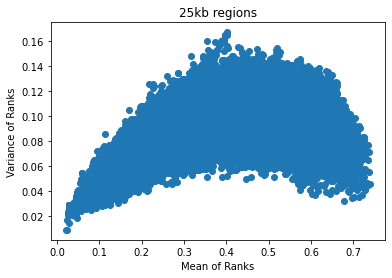

In [260]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(percents_mean, percents_var)

plt.xlabel('Mean of Ranks')
plt.ylabel('Variance of Ranks')

plt.title('25kb regions')

In [273]:
np.where((percents_mean < 0.5) & (percents_mean > 0.4) & (percents_var < 0.06))[0]

array([  330,  5499,  8272,  8700, 10500, 19429, 23661, 23720, 24419,
       24450, 27747, 32219, 43673, 47119, 48954, 51230, 65183, 70300,
       70305, 70513, 77270, 83009, 87976])

In [264]:
percents[330]

array([0.4875055 , 0.49839112, 0.6184529 , 0.6514054 , 0.6446661 ,
       0.5883553 , 0.6141017 , 0.7483386 , 0.7177666 , 0.72707015,
       0.66060126, 0.51672333, 0.2781619 , 0.3459922 , 0.6778117 ,
       0.6903392 , 0.2976108 , 0.37038738, 0.55240834, 0.6931923 ,
       0.        , 0.        , 0.        , 0.        , 0.56296843,
       0.6979373 , 0.4507582 , 0.47056073, 0.35605565, 0.3847397 ,
       0.8367645 , 0.55418473, 0.55628294, 0.11738342], dtype=float32)

In [270]:
regions_sep[330]

array(['chr1', '10978343', '11003343'], dtype='<U9')

In [ ]:
chr1:10978343-11003343

In [272]:
percents[24419]

array([0.41133156, 0.40474424, 0.26169366, 0.5093966 , 0.8751563 ,
       0.38174474, 0.42626768, 0.37641135, 0.64403313, 0.5996633 ,
       0.88654476, 0.5369747 , 0.18598571, 0.7038248 , 0.72089624,
       0.5631115 , 0.3211998 , 0.61758035, 0.32932445, 0.61342704,
       0.16603976, 0.347022  , 0.6099373 , 0.53381836, 0.62296313,
       0.676497  , 0.5118465 , 0.        , 0.        , 0.35586312,
       0.41499475, 0.20800434, 0.34025034, 0.        ], dtype=float32)

In [271]:
regions_sep[24419]

array(['chr14', '91920456', '91945456'], dtype='<U9')

In [ ]:
chr14:91920456-91945456

In [274]:
percents[43673]

array([8.2504100e-01, 7.7934438e-01, 5.4878867e-01, 6.2379193e-01,
       4.9748755e-01, 4.0992919e-01, 7.3095655e-01, 5.7120520e-01,
       3.9527965e-01, 3.6858532e-01, 6.5686828e-01, 4.2408347e-01,
       2.6465666e-01, 2.7118993e-01, 7.7228522e-01, 4.8240176e-01,
       0.0000000e+00, 2.8716653e-04, 3.1369281e-01, 1.3288563e-01,
       2.2508806e-01, 2.4621378e-01, 4.8719895e-01, 1.7556764e-01,
       1.6144510e-01, 4.0886813e-01, 1.8750988e-01, 5.2488554e-01,
       3.4947997e-01, 0.0000000e+00, 6.3171881e-01, 6.4952624e-01,
       7.3410738e-01, 0.0000000e+00], dtype=float32)

In [275]:
regions_sep[43673]

array(['chr2', '239027504', '239052504'], dtype='<U9')

In [ ]:
chr2:239027504-239052504

In [331]:
np.where((percents_mean < 0.025))[0]

array([ 8183, 30929, 62674])

In [338]:
percents[62674]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.2940452 , 0.        ,
       0.        , 0.        , 0.        , 0.48948416], dtype=float32)

In [339]:
regions_sep[62674]

array(['chr5', '99194496', '99219496'], dtype='<U9')

In [ ]:
chr5:99194496-99219496

In [323]:
149722740-149747939

-25199